# 04 Train the one shot predictor (raw radar features to sphere parameters)

A small CNN (`OneShotNet` in 00_common) learns `[x, y, z, r]` from the features. Split 90 / 5 / 5 with a fixed seed. The test set is never used for choosing the model. Baseline: always predicting the mean of the training parameters.

In [1]:
%run ./00_common.ipynb

C:\Users\Rey\anaconda3\envs\kolb\Lib\site-packages\nbformat\validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


PROJECT  : C:\Users\Rey\Documents\Kolb_Radar_Project
FAKE_MODE: False
[mitsuba] Warning: Couldn't import the ipywidgets package. Installing this package is required for the system to properly log messages and print in Jupyter notebooks!


torch device: cuda
mitsuba variant: cuda_ad_rgb


Switched off Tx:  2
Switched off Rx:  10
torch 2.5.1+cu121 | device cuda
common ready


In [2]:
if FAKE_MODE and not list(DATA.glob('shard_*.npz')):
    P = sample_params(2000, np.random.default_rng(0)); X = np.stack([fake_features(p) for p in P])
else:
    X, P = load_dataset()
tr, va, te = split_indices(len(X))
Xtr, Ptr = X[tr], P[tr]; Xva, Pva = X[va], P[va]; Xte, Pte = X[te], P[te]
print('train', len(tr), 'val', len(va), 'test', len(te))
base = mae_mm(np.repeat(to_unit(Ptr.mean(0, keepdims=True)), len(te), 0), Pte)
print('mean baseline MAE (mm):', base)

train 4590 val 255 test 255
mean baseline MAE (mm): {'x': 58.445003509521484, 'y': 10.211849212646484, 'z': 10.193244934082031, 'r': 3.726912260055542}


In [3]:
EPOCHS = int(os.environ.get('KOLB_EPOCHS', '60')); BS = 128; LR = 1e-3
torch.manual_seed(SEED)
model = OneShotNet().to(DEVICE)
opt_ = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt_, max_lr=LR, total_steps=EPOCHS * math.ceil(len(tr) / BS))
Xt = torch.from_numpy(Xtr.astype(np.float32)); Yt = torch.from_numpy(to_unit(Ptr).astype(np.float32))
Xv = Xva.astype(np.float32)
best, hist = float('inf'), []
t0 = time.time()
for ep in range(EPOCHS):
    model.train(); perm = torch.randperm(len(Xt)); tot = 0.0
    for i in range(0, len(Xt), BS):
        b = perm[i:i+BS]
        xb = Xt[b].to(DEVICE); yb = Yt[b].to(DEVICE)
        xb = xb * (1 + 0.05 * torch.randn(len(b), 1, 1, 1, device=DEVICE)) + 0.01 * torch.randn_like(xb)  # light noise augmentation
        loss = nn.functional.smooth_l1_loss(model(xb), yb, beta=0.02)
        opt_.zero_grad(); loss.backward(); opt_.step(); sched.step(); tot += loss.item() * len(b)
    v = evaluate(model, Xv, Pva); vm = float(np.mean(list(v.values())))
    hist.append({'epoch': ep + 1, 'train_loss': tot / len(Xt), 'val_mae_mm': v})
    if vm < best:
        best = vm; torch.save(model.state_dict(), MODELS / 'oneshot_fp32.pt')
    if ep % 5 == 0 or ep == EPOCHS - 1:
        print(f'epoch {ep+1}: loss {tot/len(Xt):.5f} | val MAE mm {v}')
print('training time', round(time.time() - t0), 's')

epoch 1: loss 0.17499 | val MAE mm {'x': 43.78519058227539, 'y': 9.999618530273438, 'z': 8.827486038208008, 'r': 3.3585638999938965}


epoch 6: loss 0.14114 | val MAE mm {'x': 6.485477924346924, 'y': 10.150345802307129, 'z': 5.525761127471924, 'r': 2.76778244972229}


epoch 11: loss 0.09514 | val MAE mm {'x': 8.069218635559082, 'y': 10.38684368133545, 'z': 9.034202575683594, 'r': 4.879193305969238}


epoch 16: loss 0.08450 | val MAE mm {'x': 12.388574600219727, 'y': 11.547630310058594, 'z': 12.88186264038086, 'r': 6.171525955200195}


epoch 21: loss 0.08123 | val MAE mm {'x': 14.96645736694336, 'y': 12.560396194458008, 'z': 12.699199676513672, 'r': 5.957653999328613}


...

epoch 41: loss 0.07115 | val MAE mm {'x': 5.545334339141846, 'y': 12.66478443145752, 'z': 5.786599159240723, 'r': 3.899688959121704}


epoch 46: loss 0.07047 | val MAE mm {'x': 5.234298229217529, 'y': 12.123736381530762, 'z': 4.290911674499512, 'r': 3.2140092849731445}


epoch 51: loss 0.06635 | val MAE mm {'x': 4.400472164154053, 'y': 13.100481986999512, 'z': 5.566992282867432, 'r': 3.434718132019043}


epoch 56: loss 0.06462 | val MAE mm {'x': 4.042342662811279, 'y': 12.607061386108398, 'z': 5.174971580505371, 'r': 3.1590960025787354}


epoch 60: loss 0.06345 | val MAE mm {'x': 3.938702344894409, 'y': 12.72121810913086, 'z': 4.886462211608887, 'r': 3.114370822906494}
training time 12 s


In [4]:
model.load_state_dict(torch.load(MODELS / 'oneshot_fp32.pt', map_location=DEVICE))
val_before = evaluate(model, Xv, Pva)
# BatchNorm recalibration on CLEAN training inputs: the running statistics were collected on noise augmented
# inputs during training, which leaves a constant offset at test time (seen as a bias in z and r).
for m in model.modules():
    if isinstance(m, nn.BatchNorm2d):
        m.reset_running_stats(); m.momentum = None      # cumulative average over the recalibration pass
model.train()
with torch.no_grad():
    for i in range(0, len(Xt), 256):
        model(Xt[i:i+256].to(DEVICE))
model.eval()
val_after = evaluate(model, Xv, Pva)
print('validation MAE mm before BN recalibration', val_before, '| after', val_after)
torch.save(model.state_dict(), MODELS / 'oneshot_fp32.pt')
with torch.no_grad():
    _pte = from_unit(model(torch.from_numpy(Xte.astype(np.float32)).to(DEVICE)).cpu().numpy())
test_bias = dict(zip(PARAM_NAMES, ((_pte - Pte) * 1000).mean(0).round(3).tolist()))
print('test signed bias mm', test_bias)
test = evaluate(model, Xte.astype(np.float32), Pte)
# speed: one sample, batch 1, after warm up
x1 = torch.from_numpy(Xte[:1].astype(np.float32)).to(DEVICE); model.eval()
with torch.no_grad():
    for _ in range(20): model(x1)
    if DEVICE == 'cuda': torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(200): model(x1)
    if DEVICE == 'cuda': torch.cuda.synchronize()
ms = (time.time() - t0) / 200 * 1000
n_params = sum(p.numel() for p in model.parameters())
res = {'test_mae_mm': test, 'test_bias_mm': test_bias, 'val_mae_before_bn_recal': val_before, 'val_mae_after_bn_recal': val_after, 'mean_baseline_mae_mm': base, 'ms_per_prediction': ms, 'n_params': n_params,
       'fp32_weight_kb': n_params * 4 / 1024, 'n_train': len(tr), 'n_test': len(te), 'epochs': EPOCHS, 'history': hist,
       'fake_mode': FAKE_MODE}
save_json(res, '04_predictor.json')
print('TEST MAE (mm):', test, '| baseline:', base, f'| {ms:.2f} ms per prediction | {n_params} parameters')
log(f'04 predictor test MAE mm {test}, {ms:.2f} ms per prediction')

validation MAE mm before BN recalibration {'x': 2.947399616241455, 'y': 10.080053329467773, 'z': 5.577317714691162, 'r': 2.708315134048462} | after {'x': 3.1212892532348633, 'y': 10.085382461547852, 'z': 5.538700103759766, 'r': 2.7274978160858154}
test signed bias mm {'x': 1.1009999513626099, 'y': 0.3700000047683716, 'z': -1.7920000553131104, 'r': -0.39800000190734863}


saved C:\Users\Rey\Documents\Kolb_Radar_Project\outputs\results\04_predictor.json
TEST MAE (mm): {'x': 2.7962286472320557, 'y': 10.188100814819336, 'z': 5.112585067749023, 'r': 2.5817832946777344} | baseline: {'x': 58.445003509521484, 'y': 10.211849212646484, 'z': 10.193244934082031, 'r': 3.726912260055542} | 0.36 ms per prediction | 883428 parameters
2026-10-27 01:12:23  04 predictor test MAE mm {'x': 2.7962286472320557, 'y': 10.188100814819336, 'z': 5.112585067749023, 'r': 2.5817832946777344}, 0.36 ms per prediction


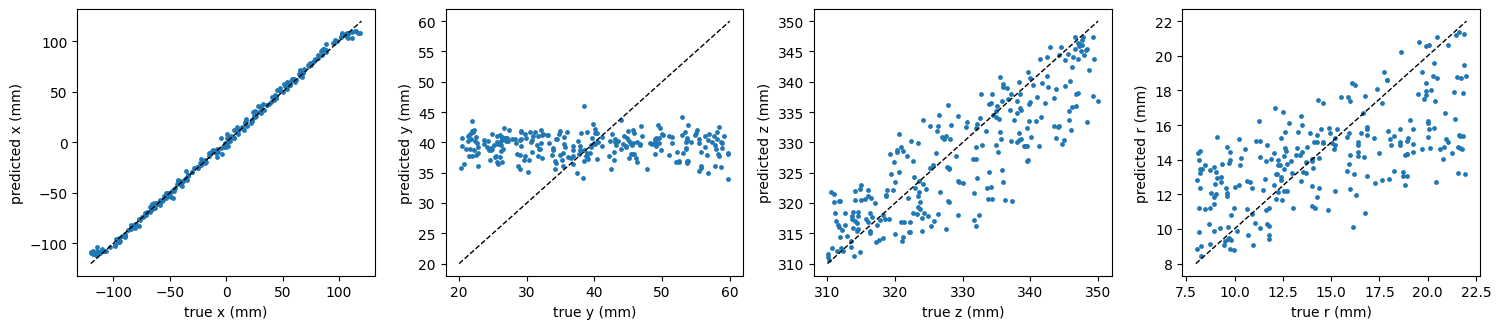

In [5]:
import matplotlib.pyplot as plt
with torch.no_grad():
    pred = from_unit(model(torch.from_numpy(Xte.astype(np.float32)).to(DEVICE)).cpu().numpy())
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
for i, k in enumerate(PARAM_NAMES):
    ax[i].scatter(Pte[:, i] * 1000, pred[:, i] * 1000, s=6); lo, hi = LOW[i] * 1000, HIGH[i] * 1000
    ax[i].plot([lo, hi], [lo, hi], 'k--', lw=1); ax[i].set_xlabel(f'true {k} (mm)'); ax[i].set_ylabel(f'predicted {k} (mm)')
plt.tight_layout(); plt.savefig(FIGS / '04_pred_vs_true.png', dpi=120); plt.show()